# Tabular — Strategi Validasi
**Kapan dipakai:** ingin tahu cara mengukur model yang bisa dipercaya sebelum submit.

**Isi:**
1. Cross validation (CV): data dibagi beberapa bagian (fold), model diuji bergantian di
   tiap fold. Skor rata-rata lebih stabil daripada satu kali split.
2. Adversarial validation: apakah data train dan test mirip? Kalau tidak mirip, skor CV
   bisa menipu.

**Data demo:** Titanic (target `survived`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, KFold, RepeatedStratifiedKFold
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit
from sklearn.model_selection import RepeatedKFold, StratifiedShuffleSplit
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/tabular/classification"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/titanic_train.csv"
TEST_CSV = f"{DATA_FOLDER}/titanic_test.csv"

TARGET = "survived"
NUM_COLS = ["pclass", "age", "sibsp", "parch", "fare"]
CAT_COLS = ["sex", "embarked", "who", "deck"]
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (712, 16) | test: (179, 15)


,id,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,693,1,3,male,NaN,0,0,56.4958,S,Third,man,True,NaN,Southampton,yes,True
1,482,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True
2,528,0,1,male,NaN,0,0,221.7792,S,First,man,True,C,Southampton,no,True
3,856,1,3,female,18.0,0,1,9.3500,S,Third,woman,False,NaN,Southampton,yes,False
4,802,1,2,female,31.0,1,1,26.2500,S,Second,woman,False,NaN,Southampton,yes,False


## Model yang diuji
Model sederhana saja: fokus notebook ini adalah cara mengukur, bukan modelnya.

In [4]:
num_steps = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
cat_steps = make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore"))
preprocess = ColumnTransformer([
    ("num", num_steps, NUM_COLS),
    ("cat", cat_steps, CAT_COLS),
])
pipe = make_pipeline(preprocess, LogisticRegression(max_iter=2000))

X = train[NUM_COLS + CAT_COLS]
y = train[TARGET]

## 1. Cross validation
Pilih SATU `cv`: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.
- Satu orang/pelanggan punya banyak baris → `GroupKFold`, pakai baris `scores` kedua dan
  isi `groups=train["kolom_grup"]`.
- Data berurutan waktu → `TimeSeriesSplit` (urutkan data menurut waktu dulu).

In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)     # proporsi label sama di tiap fold
# cv = KFold(5, shuffle=True, random_state=SEED)
# cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
# cv = GroupKFold(5)
# cv = TimeSeriesSplit(5)
# cv = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=SEED)
# cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)

scores = cross_val_score(pipe, X, y, cv=cv, scoring="f1_macro")
# scores = cross_val_score(pipe, X, y, cv=GroupKFold(5), groups=train["kolom_grup"],
#                          scoring="f1_macro")
print("skor per fold:", np.round(scores, 4))
print("rata-rata:", round(scores.mean(), 4), "± simpangan", round(scores.std(), 4))

skor per fold: [0.8147 0.7752 0.8483 0.7668 0.8248]
rata-rata: 0.806 ± simpangan 0.0307


## 2. Adversarial validation
Gabungkan train dan test, beri label asal: 0 = dari train, 1 = dari test.
Lalu latih model untuk menebak asal baris.
- AUC ≈ 0.5: model tidak bisa membedakan → train dan test mirip, CV bisa dipercaya.
- AUC jauh di atas 0.5: ada feature yang berbeda → lihat gambar feature teratas.

In [6]:
combined = pd.concat([train[NUM_COLS + CAT_COLS], test[NUM_COLS + CAT_COLS]],
                     ignore_index=True)
origin = np.concatenate([np.zeros(len(train)), np.ones(len(test))])

adversarial_pipe = make_pipeline(preprocess, LGBMClassifier(n_estimators=200, verbose=-1))
folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
probabilities = cross_val_predict(adversarial_pipe, combined, origin, cv=folds,
                                  method="predict_proba")
print("AUC adversarial:", round(roc_auc_score(origin, probabilities[:, 1]), 4))

AUC adversarial: 0.542


Feature yang paling membantu model membedakan train dan test.

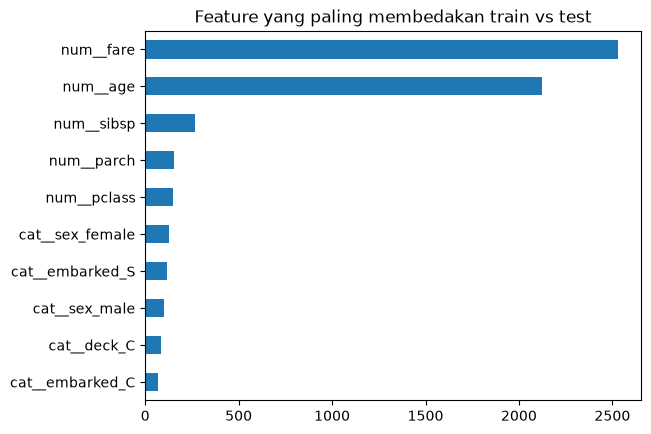

In [7]:
adversarial_pipe.fit(combined, origin)
feature_names = adversarial_pipe[0].get_feature_names_out()
importance = pd.Series(adversarial_pipe[-1].feature_importances_, index=feature_names)
importance = importance.sort_values()
importance.tail(10).plot.barh()
plt.title("Feature yang paling membedakan train vs test")
plt.show()

## Latih ulang di semua data + submission

In [8]:
pipe.fit(X, y)
predictions = pipe.predict(test[NUM_COLS + CAT_COLS])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["survived"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,survived
0,566,0
1,161,0
2,554,0
3,861,0
4,242,1
